# Observed versus modeled surface mass balance at the Spaulding sites

**Reviewer 1, Comment 1 — executed diagnostic and draft supplementary figure**

This notebook makes the direct cross plot requested in the review: observed surface mass balance on the vertical axis and modeled surface mass balance on the horizontal axis, evaluated at the same Spaulding pole coordinates.

The 80 m borehole mesh does not contain any Spaulding pole. We therefore use the saved 800 m regional parent solution that supplied the fine-mesh boundary conditions. This is the only installed model solution that overlaps the pole network. No value is extrapolated outside its domain, and no manuscript or rebuttal file is modified.

## Diagnostic equation

For surface elevation $z=h(x,y,t)$, the kinematic boundary condition is

$$
\frac{\partial h}{\partial t}
+u_s\frac{\partial h}{\partial x}
+v_s\frac{\partial h}{\partial y}
-w_s=\dot a,
$$

where $w_s$ is positive upward and $\dot a$ is positive for accumulation. We define the modeled surface mass balance implied by stationary geometry as

$$
\boxed{\dot a_{\rm modeled}
=u_s\frac{\partial h}{\partial x}
+v_s\frac{\partial h}{\partial y}-w_s.}
$$

The cross-plot residual has a direct interpretation:

$$
\dot a_{\rm observed}-\dot a_{\rm modeled}=\frac{\partial h}{\partial t}.
$$

Thus the one-to-one line represents consistency between the modeled flow, observed surface balance, and a stationary surface.

In [1]:
# The supplied x86 Firedrake image includes an optional Netgen binary that is
# unusable under Apple emulation. This calculation uses RectangleMesh only.
import sys
sys.modules["netgen"] = None

from pathlib import Path
from hashlib import sha256
import json
import math
import platform

import h5py
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from scipy.stats import pearsonr, spearmanr


def locate_model_root() -> Path:
    '''Locate a staged or installed AH_temp_paper model root.'''
    candidates = [Path.cwd(), *Path.cwd().parents, Path("/root/AH_temp_paper")]
    for candidate in candidates:
        roots = (candidate, candidate / "AH_temp_paper")
        for root in roots:
            required = (
                root / "Saved_Models/coarse_mesh_flow.h5",
                root / "notebooks/reviewer1_comment1_inputs/regional_800m_geometry.csv",
                root / "notebooks/reviewer1_comment1_inputs/spaulding_table_s4.csv",
            )
            if all(path.is_file() for path in required):
                return root
    raise FileNotFoundError("Could not locate the staged 800 m model and Spaulding input.")


def file_sha256(path: Path) -> str:
    digest = sha256()
    with path.open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


ROOT = locate_model_root()
NOTEBOOKS = ROOT / "notebooks"
sys.path.insert(0, str(NOTEBOOKS))
import reviewer1_comment1_model as model_io

CHECKPOINT = ROOT / "Saved_Models/coarse_mesh_flow.h5"
GEOMETRY = NOTEBOOKS / "reviewer1_comment1_inputs/regional_800m_geometry.csv"
OBSERVATIONS = NOTEBOOKS / "reviewer1_comment1_inputs/spaulding_table_s4.csv"
OUTPUT_DIR = NOTEBOOKS / "reviewer1_comment1_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

EXPECTED_HASHES = {
    CHECKPOINT: "a6faad176f96276c9c1500308f3a43b58ed16f7504be0ca0baf71f3cfc09d724",
    GEOMETRY: "0a6ed7c47a0108745dd1ebc8f3024e8bc03e24d394e196d7d1904cd51a47b126",
    OBSERVATIONS: "6b206e2b0c86975b0bc4f8349e963e1f6cd30336d9a45e24bfc7fb113706a7c0",
}

provenance_rows = []
for path, expected in EXPECTED_HASHES.items():
    observed = file_sha256(path)
    if observed != expected:
        raise RuntimeError(f"SHA-256 mismatch for {path}: {observed} != {expected}")
    provenance_rows.append({"input": path.name, "sha256": observed})

display(pd.DataFrame(provenance_rows))
print(f"Model root: {ROOT}")
print(f"Python {platform.python_version()}; NumPy {np.__version__}; Matplotlib {mpl.__version__}")
print("All source hashes match the locked inputs.")

,input,sha256
0,coarse_mesh_flow.h5,a6faad176f96276c9c1500308f3a43b58ed16f7504be0c...
1,regional_800m_geometry.csv,0a6ed7c47a0108745dd1ebc8f3024e8bc03e24d394e196...
2,spaulding_table_s4.csv,6b206e2b0c86975b0bc4f8349e963e1f6cd30336d9a45e...


Model root: /tmp/reviewer1-comment1.BkIzSV
Python 3.12.3; NumPy 2.2.5; Matplotlib 3.10.1
All source hashes match the locked inputs.


## Observations and site selection

The observational input is a normalized snapshot of Table S4 from the USAP-DC dataset *GPS Ice Flow Measurements, Allan Hills, Antarctica* (DOI [10.7265/N5NS0RSX](https://doi.org/10.7265/N5NS0RSX)). The associated paper is Spaulding et al. (2012), DOI [10.3189/2012JoG11J176](https://doi.org/10.3189/2012JoG11J176).

Table S4 contains 55 finite apparent surface-balance values. Spaulding et al. omit the 30 snow-plain values from their reported mass-balance comparison because snow density, migrating sastrugi, and short-term accumulation variability produce large uncertainty. The paper-retained comparison therefore comprises 25 ice/firn sites with surface density $\geq0.8$ Mg m$^{-3}$. The regional model contains 24 of these 25 sites; M16 lies outside the domain. The draft figure shows all 47 finite archived values that can be evaluated without extrapolation, while visually distinguishing the 24 paper-retained ice/firn sites from the 23 snow-plain sensitivity points.

In [2]:
observations = pd.read_csv(OBSERVATIONS)
required_columns = {
    "pole_id", "x_m", "y_m", "surface_elevation_m",
    "observed_smb_m_ice_eq_yr", "observed_smb_one_sigma_m_yr",
    "surface_density_Mg_m3",
}
missing = sorted(required_columns.difference(observations.columns))
if missing:
    raise RuntimeError(f"Spaulding snapshot is missing columns: {missing}")
if len(observations) != 58 or observations["pole_id"].duplicated().any():
    raise RuntimeError("Spaulding snapshot must contain 58 uniquely named coordinate rows.")

observations["observed_finite"] = observations["observed_smb_m_ice_eq_yr"].notna()
observations["paper_retained_ice_or_firn"] = (
    observations["observed_finite"]
    & observations["surface_density_Mg_m3"].ge(0.8)
)
observations["snow_plain_sensitivity"] = (
    observations["observed_finite"]
    & observations["surface_density_Mg_m3"].eq(0.4)
)

input_counts = pd.Series({
    "coordinate rows": len(observations),
    "finite archived balances": int(observations["observed_finite"].sum()),
    "paper-retained ice/firn balances": int(observations["paper_retained_ice_or_firn"].sum()),
    "snow-plain apparent balances (sensitivity only)": int(observations["snow_plain_sensitivity"].sum()),
    "rows without a balance": int((~observations["observed_finite"]).sum()),
})
display(input_counts.to_frame("count"))

,count
coordinate rows,58
finite archived balances,55
paper-retained ice/firn balances,25
snow-plain apparent balances (sensitivity only),30
rows without a balance,3


## Reconstruct and load the 800 m regional parent solution

The regional geometry is reconstructed from a hash-locked snapshot of the 26 by 38 horizontal grid produced from the original EPSG:3031 DEMs. The snapshot records every bed and surface value used by the regional model, avoiding a dependency on 123 MB of source rasters that are absent from the public repository. Five terrain-following layers reproduce the saved serial checkpoint's CG3 three-component velocity and CG1 pressure field. The input documentation records the source-raster hashes and exact snapshot exporter.

The regional checkpoint is used without the factor of 1.97 applied later in the fine-field Figure 3 plotting workflow. Source code does not apply that factor to the coarse boundary-conditioning solve. A 1.97-scaled sensitivity is nevertheless reported below.

In [3]:
bundle = model_io.build_mesh_from_geometry(GEOMETRY)
fd = bundle["firedrake"]
mesh = bundle["mesh"]

pressure_space = fd.FunctionSpace(mesh, "CG", 1)
velocity_space = fd.VectorFunctionSpace(mesh, "CG", 3)
mixed_space = velocity_space * pressure_space

with h5py.File(CHECKPOINT, "r") as checkpoint_file:
    field_length = int(checkpoint_file["fields/coarse_mesh_flow"].shape[0])
    checkpoint_ranks = int(checkpoint_file.attrs["nprocs"])
if checkpoint_ranks != 1 or field_length != int(mixed_space.dim()):
    raise RuntimeError(
        f"Checkpoint/mesh mismatch: ranks={checkpoint_ranks}, "
        f"field={field_length}, space={mixed_space.dim()}"
    )

from firedrake.checkpointing import DumbCheckpoint, FILE_READ
flow = fd.Function(mixed_space)
checkpoint = DumbCheckpoint(str(CHECKPOINT.with_suffix("")), mode=FILE_READ)
checkpoint.load(flow, name="coarse_mesh_flow")
checkpoint.close()
velocity = flow.subfunctions[0]

base_surface = bundle["base_surface"]
base_mesh = base_surface.function_space().mesh()
gradient_space = fd.VectorFunctionSpace(base_mesh, "DG", 0)
surface_gradient = fd.Function(gradient_space, name="coarse_surface_gradient")
surface_gradient.interpolate(fd.grad(base_surface))

columns = model_io.mesh_columns_from_coordinates(
    np.asarray(mesh.coordinates.dat.data_ro, dtype=float)
)
model_summary = pd.Series({
    "resampled horizontal grid": " × ".join(map(str, bundle["resampled_shape"])),
    "horizontal surface nodes": len(columns),
    "vertical layers": model_io.MESH_LAYERS,
    "mixed-space unknowns": int(mixed_space.dim()),
    "checkpoint MPI ranks": checkpoint_ranks,
    "x minimum (km)": columns["x_m"].min() / 1000,
    "x maximum (km)": columns["x_m"].max() / 1000,
    "y minimum (km)": columns["y_m"].min() / 1000,
    "y maximum (km)": columns["y_m"].max() / 1000,
})
display(model_summary.to_frame("value"))

/opt/firedrake/firedrake/checkpointing.py:103: DeprecationWarning: DumbCheckpoint class will soon be deprecated; use CheckpointFile class instead.
  warnings.warn("DumbCheckpoint class will soon be deprecated; use CheckpointFile class instead.",


,value
resampled horizontal grid,26 × 38
horizontal surface nodes,988
vertical layers,5
mixed-space unknowns,414504
checkpoint MPI ranks,1
x minimum (km),501.959884
x maximum (km),532.276515
y minimum (km),-1362.607172
y maximum (km),-1342.322557


## Evaluate the model at each pole coordinate

At every in-domain pole, surface elevation is evaluated from the coarse CG1 surface. Its horizontal gradient is the exact piecewise-constant gradient in the containing surface triangle. The three-component velocity is then evaluated at $(x_i,y_i,h_i)$, and

$$
\dot a_{{\rm modeled},i}
=\left(u_i h_{x,i}+v_i h_{y,i}-w_i\right)(365.25\times24\times3600).
$$

Points outside the model raise a domain error and remain missing. They are not projected to the boundary or assigned an extrapolated value.

In [4]:
SECONDS_PER_YEAR = 365.25 * 24 * 60 * 60

evaluated_rows = []
for row in observations.itertuples(index=False):
    result = {
        "modeled_surface_elevation_m": np.nan,
        "modeled_dh_dx": np.nan,
        "modeled_dh_dy": np.nan,
        "modeled_u_surface_m_yr": np.nan,
        "modeled_v_surface_m_yr": np.nan,
        "modeled_w_surface_m_yr": np.nan,
        "modeled_smb_m_yr": np.nan,
        "modeled_smb_scaled_1p97_m_yr": np.nan,
        "model_evaluation_ok": False,
        "model_evaluation_error": "",
    }
    try:
        xy = (float(row.x_m), float(row.y_m))
        h_model = float(np.asarray(base_surface.at(xy), dtype=float).reshape(-1)[0])
        gradient = np.asarray(surface_gradient.at(xy), dtype=float).reshape(-1)
        uvw = np.asarray(
            velocity.at((xy[0], xy[1], h_model)), dtype=float
        ).reshape(-1)
        if gradient.size != 2 or uvw.size != 3 or not np.isfinite(np.r_[h_model, gradient, uvw]).all():
            raise RuntimeError("Non-finite or incorrectly shaped model evaluation.")
        uvw_m_yr = uvw * SECONDS_PER_YEAR
        modeled_smb = uvw_m_yr[0] * gradient[0] + uvw_m_yr[1] * gradient[1] - uvw_m_yr[2]
        result.update({
            "modeled_surface_elevation_m": h_model,
            "modeled_dh_dx": gradient[0],
            "modeled_dh_dy": gradient[1],
            "modeled_u_surface_m_yr": uvw_m_yr[0],
            "modeled_v_surface_m_yr": uvw_m_yr[1],
            "modeled_w_surface_m_yr": uvw_m_yr[2],
            "modeled_smb_m_yr": modeled_smb,
            "modeled_smb_scaled_1p97_m_yr": 1.97 * modeled_smb,
            "model_evaluation_ok": True,
        })
    except Exception as error:
        result["model_evaluation_error"] = f"{type(error).__name__}: {error}"
    evaluated_rows.append(result)

evaluation = pd.concat(
    [observations.reset_index(drop=True), pd.DataFrame(evaluated_rows)], axis=1
)
evaluation["implied_dh_dt_m_yr"] = (
    evaluation["observed_smb_m_ice_eq_yr"]
    - evaluation["modeled_smb_m_yr"]
)
evaluation["pole_group"] = (
    evaluation["pole_id"].str.extract(r"^([A-Za-z]+)", expand=False).str.upper()
)
evaluation.to_csv(OUTPUT_DIR / "spaulding_observed_vs_modeled_sites.csv", index=False)

primary = evaluation[
    evaluation["paper_retained_ice_or_firn"]
    & evaluation["model_evaluation_ok"]
].copy()
snow_sensitivity = evaluation[
    evaluation["snow_plain_sensitivity"]
    & evaluation["model_evaluation_ok"]
].copy()
all_crossplot = evaluation[
    evaluation["observed_finite"]
    & evaluation["model_evaluation_ok"]
].copy()
off_domain = evaluation[
    evaluation["observed_finite"]
    & ~evaluation["model_evaluation_ok"]
].copy()
expected_off_domain_ids = {f"M{number:02d}" for number in range(9, 17)}
observed_off_domain_ids = set(off_domain["pole_id"])
if observed_off_domain_ids != expected_off_domain_ids:
    raise RuntimeError(
        "Unexpected model-evaluation failures: "
        f"expected {sorted(expected_off_domain_ids)}, found {sorted(observed_off_domain_ids)}"
    )

qa = pd.Series({
    "finite observed sites evaluated by model": len(all_crossplot),
    "paper-retained ice/firn sites plotted": len(primary),
    "snow-plain sensitivity sites plotted": len(snow_sensitivity),
    "finite observed sites outside model": len(off_domain),
    "paper-retained sites outside model": int(
        (off_domain["surface_density_Mg_m3"] >= 0.8).sum()
    ),
})
display(qa.to_frame("count"))
print("Outside-domain finite sites:", ", ".join(off_domain["pole_id"]))
display(off_domain[["pole_id", "model_evaluation_error"]])

,count
finite observed sites evaluated by model,47
paper-retained ice/firn sites plotted,24
snow-plain sensitivity sites plotted,23
finite observed sites outside model,8
paper-retained sites outside model,1


Outside-domain finite sites: M09, M10, M11, M12, M13, M14, M15, M16


,pole_id,model_evaluation_error
22,M09,PointNotInDomainError: domain <Mesh #0> does n...
23,M10,PointNotInDomainError: domain <Mesh #0> does n...
24,M11,PointNotInDomainError: domain <Mesh #0> does n...
25,M12,PointNotInDomainError: domain <Mesh #0> does n...
26,M13,PointNotInDomainError: domain <Mesh #0> does n...
27,M14,PointNotInDomainError: domain <Mesh #0> does n...
28,M15,PointNotInDomainError: domain <Mesh #0> does n...
29,M16,PointNotInDomainError: domain <Mesh #0> does n...


## Cross-plot statistics

The primary statistics use the 24 paper-retained ice/firn sites with model support. They are descriptive because neighboring poles are spatially related and model-side uncertainty is not available. Observational error bars show the reported one-standard-deviation uncertainty; no horizontal error bar is invented. Pearson and Spearman correlations are reported without fitting a regression line.

In [5]:
def comparison_metrics(frame, model_column, label):
    observed = frame["observed_smb_m_ice_eq_yr"].to_numpy(float)
    modeled = frame[model_column].to_numpy(float)
    residual = observed - modeled
    pearson = pearsonr(modeled, observed)
    spearman = spearmanr(modeled, observed)
    return {
        "model": label,
        "n": len(frame),
        "mean observed (m/yr)": observed.mean(),
        "mean modeled (m/yr)": modeled.mean(),
        "bias observed-model (m/yr)": residual.mean(),
        "MAE (m/yr)": np.mean(np.abs(residual)),
        "RMSE (m/yr)": np.sqrt(np.mean(residual**2)),
        "Pearson r": pearson.statistic,
        "Pearson p": pearson.pvalue,
        "Spearman rho": spearman.statistic,
        "Spearman p": spearman.pvalue,
    }


metrics = pd.DataFrame([
    comparison_metrics(primary, "modeled_smb_m_yr", "raw 800 m parent solution"),
    comparison_metrics(
        primary,
        "modeled_smb_scaled_1p97_m_yr",
        "1.97-scaled sensitivity",
    ),
])
display(metrics.style.format(precision=4))

site_table = primary[[
    "pole_id", "surface_density_Mg_m3",
    "modeled_smb_m_yr", "observed_smb_m_ice_eq_yr",
    "observed_smb_one_sigma_m_yr", "implied_dh_dt_m_yr",
]].sort_values("pole_id")
display(site_table.style.format(precision=4))

,model,n,mean observed (m/yr),mean modeled (m/yr),bias observed-model (m/yr),MAE (m/yr),RMSE (m/yr),Pearson r,Pearson p,Spearman rho,Spearman p
0,raw 800 m parent solution,24,-0.0257,0.0001,-0.0258,0.0467,0.0543,0.2142,0.3148,0.1975,0.3550
1,1.97-scaled sensitivity,24,-0.0257,0.0003,-0.0260,0.0842,0.0979,0.2142,0.3148,0.1975,0.3550


,pole_id,surface_density_Mg_m3,modeled_smb_m_yr,observed_smb_m_ice_eq_yr,observed_smb_one_sigma_m_yr,implied_dh_dt_m_yr
0,A01,0.9000,0.0152,-0.0304,0.0032,-0.0455
1,A02,0.9000,-0.0012,-0.0130,0.0032,-0.0117
2,A03,0.9000,-0.0418,-0.0013,0.0032,0.0405
3,A04,0.8000,-0.0801,-0.0176,0.0034,0.0625
4,A05,0.9000,-0.0030,-0.0244,0.0032,-0.0214
5,A06,0.8000,0.0578,-0.0155,0.0033,-0.0733
14,M01,0.9000,0.0482,-0.0095,0.0032,-0.0577
30,N01,0.9000,0.0575,-0.0249,0.0032,-0.0823
31,N02,0.9000,0.0562,-0.0328,0.0032,-0.0890
32,N03,0.9000,0.0544,-0.0080,0.0032,-0.0624


## Draft cross plot

Panel **a** includes every finite Table S4 balance that can be evaluated inside the installed model domain. The light gray open symbols are snow-plain apparent balances retained only to satisfy the all-site visual check; Spaulding et al. do not use them as reliable mass-balance observations. Panel **b** isolates the 24 paper-retained ice/firn sites and provides the quantitative comparison intended for the supplement.

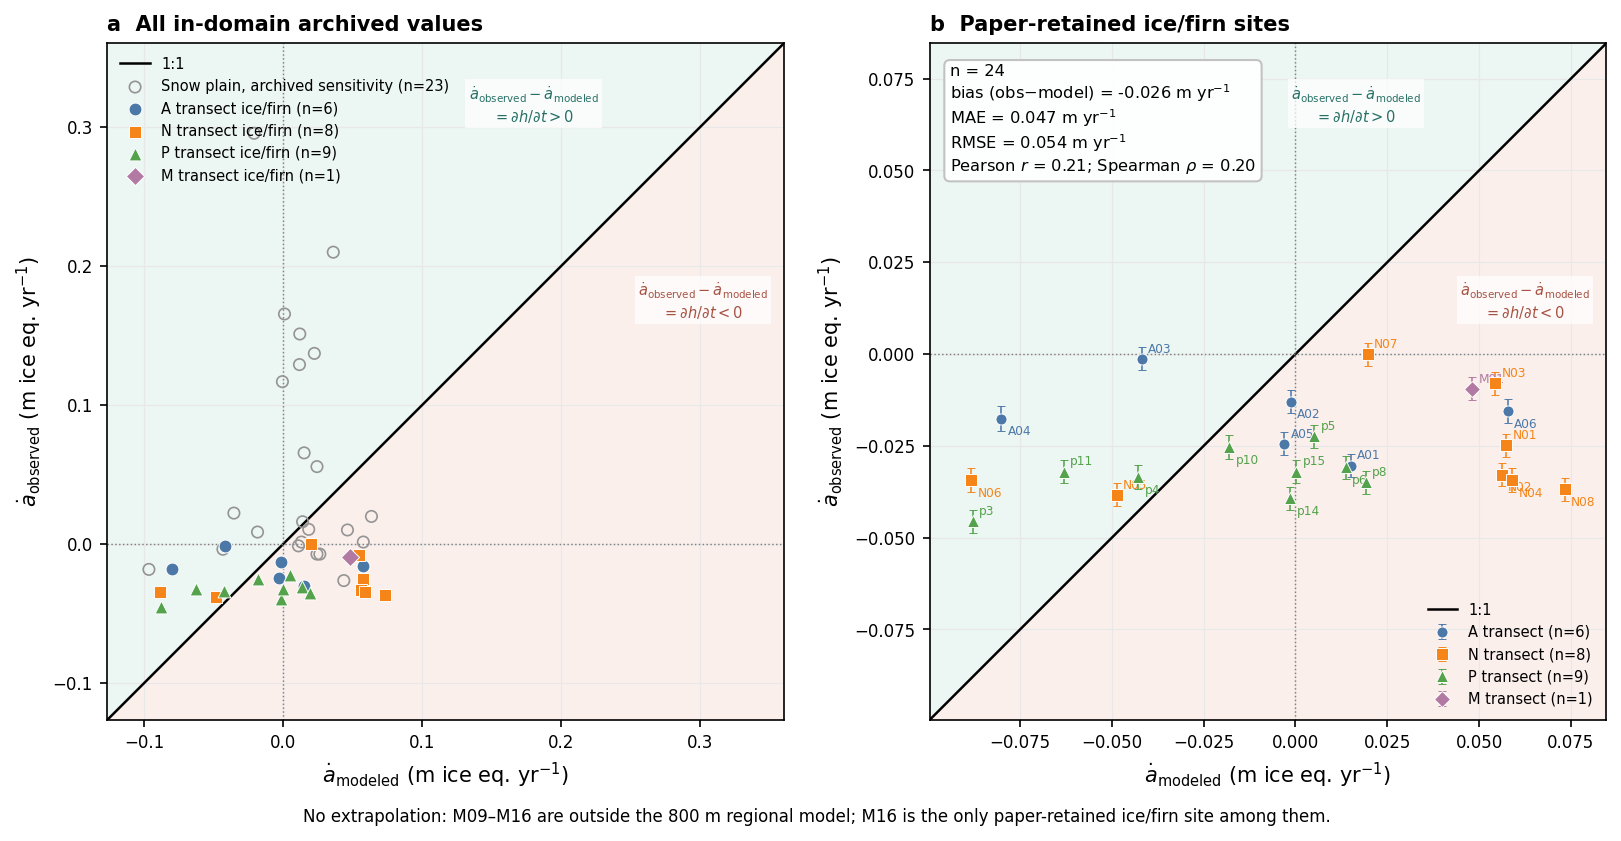

Saved /tmp/reviewer1-comment1.BkIzSV/notebooks/reviewer1_comment1_outputs/figure_spaulding_observed_vs_modeled_smb.png
Saved /tmp/reviewer1-comment1.BkIzSV/notebooks/reviewer1_comment1_outputs/figure_spaulding_observed_vs_modeled_smb.pdf


In [6]:
mpl.rcParams.update({
    "font.size": 9,
    "axes.labelsize": 10,
    "axes.titlesize": 10,
    "legend.fontsize": 8,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "figure.dpi": 150,
    "savefig.dpi": 400,
    "pdf.fonttype": 42,
})

group_styles = {
    "A": {"color": "#4C78A8", "marker": "o", "label": "A transect"},
    "N": {"color": "#F58518", "marker": "s", "label": "N transect"},
    "P": {"color": "#54A24B", "marker": "^", "label": "P transect"},
    "M": {"color": "#B279A2", "marker": "D", "label": "M transect"},
}


def square_limits(frame, model_column, include_uncertainty=True, padding=0.07):
    x = frame[model_column].to_numpy(float)
    y = frame["observed_smb_m_ice_eq_yr"].to_numpy(float)
    if include_uncertainty:
        sigma = frame["observed_smb_one_sigma_m_yr"].fillna(0).to_numpy(float)
        values = np.r_[x, y - sigma, y + sigma, 0.0]
    else:
        values = np.r_[x, y, 0.0]
    span = values.max() - values.min()
    return values.min() - padding * span, values.max() + padding * span


def reference_lines(ax, limits):
    low, high = limits
    diagonal = np.array([low, high])
    ax.fill_between(
        diagonal, diagonal, high, color="#DDEFEA", alpha=0.55,
        linewidth=0, zorder=0,
    )
    ax.fill_between(
        diagonal, low, diagonal, color="#F8E2DD", alpha=0.55,
        linewidth=0, zorder=0,
    )
    ax.plot([low, high], [low, high], color="black", linewidth=1.2, label="1:1")
    ax.axhline(0, color="0.5", linewidth=0.7, linestyle=":")
    ax.axvline(0, color="0.5", linewidth=0.7, linestyle=":")
    ax.set_xlim(limits)
    ax.set_ylim(limits)
    ax.set_aspect("equal", adjustable="box")
    ax.grid(color="0.91", linewidth=0.6)


def label_residual_regions(ax):
    label_style = {
        "transform": ax.transAxes, "ha": "center", "va": "center",
        "fontsize": 7.0, "zorder": 4,
        "bbox": {"facecolor": "white", "edgecolor": "none", "alpha": 0.72, "pad": 1.5},
    }
    ax.text(
        0.63, 0.91,
        r"$\dot a_{\mathrm{observed}}-\dot a_{\mathrm{modeled}}$" "\n"
        r"$=\partial h/\partial t>0$", color="#287066", **label_style,
    )
    ax.text(
        0.88, 0.62,
        r"$\dot a_{\mathrm{observed}}-\dot a_{\mathrm{modeled}}$" "\n"
        r"$=\partial h/\partial t<0$", color="#A75243", **label_style,
    )


fig, (ax_all, ax_primary) = plt.subplots(1, 2, figsize=(10.8, 5.25), constrained_layout=True)

# Panel a: every in-domain finite archived value.
limits_all = square_limits(all_crossplot, "modeled_smb_m_yr")
reference_lines(ax_all, limits_all)
ax_all.scatter(
    snow_sensitivity["modeled_smb_m_yr"],
    snow_sensitivity["observed_smb_m_ice_eq_yr"],
    s=30, marker="o", facecolors="none", edgecolors="0.58", linewidths=0.8,
    label=f"Snow plain, archived sensitivity (n={len(snow_sensitivity)})",
    zorder=2,
)
for group, style in group_styles.items():
    subset = primary[primary["pole_group"] == group]
    if subset.empty:
        continue
    ax_all.scatter(
        subset["modeled_smb_m_yr"], subset["observed_smb_m_ice_eq_yr"],
        s=38, marker=style["marker"], color=style["color"], edgecolor="white",
        linewidth=0.45, label=f"{style['label']} ice/firn (n={len(subset)})", zorder=3,
    )
ax_all.set_title("a  All in-domain archived values", loc="left", fontweight="bold")
ax_all.set_xlabel(r"$\dot a_{\mathrm{modeled}}$ (m ice eq. yr$^{-1}$)")
ax_all.set_ylabel(r"$\dot a_{\mathrm{observed}}$ (m ice eq. yr$^{-1}$)")
ax_all.legend(frameon=False, loc="upper left", fontsize=7)
label_residual_regions(ax_all)

# Panel b: paper-retained ice/firn values with reported vertical uncertainty.
limits_primary = square_limits(primary, "modeled_smb_m_yr")
reference_lines(ax_primary, limits_primary)
for group, style in group_styles.items():
    subset = primary[primary["pole_group"] == group]
    if subset.empty:
        continue
    ax_primary.errorbar(
        subset["modeled_smb_m_yr"],
        subset["observed_smb_m_ice_eq_yr"],
        yerr=subset["observed_smb_one_sigma_m_yr"],
        fmt=style["marker"], markersize=5.3, color=style["color"],
        markeredgecolor="white", markeredgewidth=0.45,
        ecolor=style["color"], elinewidth=0.75, capsize=1.7,
        linestyle="none", label=f"{style['label']} (n={len(subset)})", zorder=3,
    )
    for row_index, row in subset.reset_index(drop=True).iterrows():
        offset = (3, 3) if row_index % 2 == 0 else (3, -8)
        ax_primary.annotate(
            row["pole_id"],
            (row["modeled_smb_m_yr"], row["observed_smb_m_ice_eq_yr"]),
            xytext=offset, textcoords="offset points", fontsize=5.8,
            color=style["color"],
        )

raw_metrics = metrics.iloc[0]
metric_text = (
    f"n = {int(raw_metrics['n'])}\n"
    f"bias (obs−model) = {raw_metrics['bias observed-model (m/yr)']:.3f} m yr$^{{-1}}$\n"
    f"MAE = {raw_metrics['MAE (m/yr)']:.3f} m yr$^{{-1}}$\n"
    f"RMSE = {raw_metrics['RMSE (m/yr)']:.3f} m yr$^{{-1}}$\n"
    f"Pearson $r$ = {raw_metrics['Pearson r']:.2f}; Spearman $\\rho$ = {raw_metrics['Spearman rho']:.2f}"
)
ax_primary.text(
    0.03, 0.97, metric_text, transform=ax_primary.transAxes,
    ha="left", va="top", fontsize=7.8,
    bbox={"boxstyle": "round,pad=0.35", "facecolor": "white", "edgecolor": "0.75", "alpha": 0.94},
)
ax_primary.set_title("b  Paper-retained ice/firn sites", loc="left", fontweight="bold")
ax_primary.set_xlabel(r"$\dot a_{\mathrm{modeled}}$ (m ice eq. yr$^{-1}$)")
ax_primary.set_ylabel(r"$\dot a_{\mathrm{observed}}$ (m ice eq. yr$^{-1}$)")
ax_primary.legend(frameon=False, loc="lower right", fontsize=7)
label_residual_regions(ax_primary)

fig.text(
    0.5, -0.015,
    "No extrapolation: M09–M16 are outside the 800 m regional model; M16 is the only paper-retained ice/firn site among them.",
    ha="center", va="top", fontsize=8,
)

png_path = OUTPUT_DIR / "figure_spaulding_observed_vs_modeled_smb.png"
pdf_path = OUTPUT_DIR / "figure_spaulding_observed_vs_modeled_smb.pdf"
fig.savefig(png_path, bbox_inches="tight")
fig.savefig(pdf_path, bbox_inches="tight")
plt.show()
print(f"Saved {png_path}")
print(f"Saved {pdf_path}")

In [7]:
caption = f'''
**Draft supplementary figure caption.** Observed surface mass balance from Spaulding et al. (2012) plotted against the modeled surface mass balance implied by stationary geometry in the saved 800 m regional parent flow solution, $\\dot a_{{\\rm modeled}}=u_s h_x+v_s h_y-w_s$. Negative values denote ablation. The solid line is one-to-one; dotted lines mark zero. Pale green shading denotes $\\dot a_{{\\rm observed}}-\\dot a_{{\\rm modeled}}=\\partial h/\\partial t>0$, and pale red shading denotes $\\partial h/\\partial t<0$. **a,** All {len(all_crossplot)} finite archived Table S4 balances inside the regional model. Open gray points are {len(snow_sensitivity)} snow-plain apparent balances shown as a sensitivity; Spaulding et al. omit these from their reported comparison because snow density, sastrugi, and short-term accumulation variability produce large uncertainty. Colored points are the {len(primary)} paper-retained ice/firn sites. **b,** The paper-retained sites alone, with reported one-standard-deviation observational error bars and pole identifiers. Of the 25 reported ice/firn balances, M16 is outside the regional domain and is not extrapolated. The regional solution is the constant-viscosity parent calculation used to condition the later 80 m mesh; this comparison therefore does not evaluate the fine thermomechanical field. Model-side and point-to-grid representativeness uncertainties are not included.
'''
display(Markdown(caption))


**Draft supplementary figure caption.** Observed surface mass balance from Spaulding et al. (2012) plotted against the modeled surface mass balance implied by stationary geometry in the saved 800 m regional parent flow solution, $\dot a_{\rm modeled}=u_s h_x+v_s h_y-w_s$. Negative values denote ablation. The solid line is one-to-one; dotted lines mark zero. Pale green shading denotes $\dot a_{\rm observed}-\dot a_{\rm modeled}=\partial h/\partial t>0$, and pale red shading denotes $\partial h/\partial t<0$. **a,** All 47 finite archived Table S4 balances inside the regional model. Open gray points are 23 snow-plain apparent balances shown as a sensitivity; Spaulding et al. omit these from their reported comparison because snow density, sastrugi, and short-term accumulation variability produce large uncertainty. Colored points are the 24 paper-retained ice/firn sites. **b,** The paper-retained sites alone, with reported one-standard-deviation observational error bars and pole identifiers. Of the 25 reported ice/firn balances, M16 is outside the regional domain and is not extrapolated. The regional solution is the constant-viscosity parent calculation used to condition the later 80 m mesh; this comparison therefore does not evaluate the fine thermomechanical field. Model-side and point-to-grid representativeness uncertainties are not included.


## Interpretation and limitations

The requested cross plot is feasible for the regional model, but not for the 80 m fine model. The 24 paper-retained ice/firn sites show weak positive association between modeled and observed balance, while their displacement from the one-to-one line is substantial. The mean residual is negative, meaning the observed balances are more ablation-dominated than the modeled balances from this regional solution on average. This result does not by itself identify whether the discrepancy arises from surface-elevation change, velocity error, coarse surface geometry, sub-grid representativeness, or observational uncertainty.

The comparison should be read with five constraints:

1. It tests the saved 800 m constant-viscosity parent solution, not the 80 m thermomechanical field around the boreholes.
2. M16 is outside the regional model; assigning it a modeled value would require extrapolation or a larger-domain rerun.
3. The snow-plain points are shown only as an archived-data sensitivity and are not included in the primary statistics.
4. Vertical bars represent reported observational uncertainty only. No horizontal model uncertainty has been estimated.
5. Nearby poles are spatially related, so the correlation coefficients are descriptive rather than independent validation statistics.

In [8]:
summary = {
    "equation": "a_modeled = u*dh_dx + v*dh_dy - w",
    "units": "m ice equivalent per year per unit horizontal area",
    "model": "raw saved 800 m regional parent solution",
    "checkpoint_sha256": file_sha256(CHECKPOINT),
    "paper_retained_sites_total": int(observations["paper_retained_ice_or_firn"].sum()),
    "paper_retained_sites_plotted": len(primary),
    "paper_retained_site_outside_domain": "M16",
    "all_finite_archived_sites_plotted": len(all_crossplot),
    "finite_archived_sites_outside_domain": off_domain["pole_id"].tolist(),
    "bias_observed_minus_modeled_m_yr": float(metrics.iloc[0]["bias observed-model (m/yr)"]),
    "mae_m_yr": float(metrics.iloc[0]["MAE (m/yr)"]),
    "rmse_m_yr": float(metrics.iloc[0]["RMSE (m/yr)"]),
    "pearson_r": float(metrics.iloc[0]["Pearson r"]),
    "spearman_rho": float(metrics.iloc[0]["Spearman rho"]),
}
(OUTPUT_DIR / "spaulding_crossplot_summary.json").write_text(
    json.dumps(summary, indent=2, sort_keys=True) + "\n"
)
display(pd.Series(summary).to_frame("value"))

,value
equation,a_modeled = u*dh_dx + v*dh_dy - w
units,m ice equivalent per year per unit horizontal ...
model,raw saved 800 m regional parent solution
checkpoint_sha256,a6faad176f96276c9c1500308f3a43b58ed16f7504be0c...
paper_retained_sites_total,25
paper_retained_sites_plotted,24
paper_retained_site_outside_domain,M16
all_finite_archived_sites_plotted,47
finite_archived_sites_outside_domain,"[M09, M10, M11, M12, M13, M14, M15, M16]"
bias_observed_minus_modeled_m_yr,-0.025838
